# Этап 2. Базовые KPI и обзор данных

**Цель:** посчитать ключевые метрики бизнеса, дать первое представление
о том, что происходит с продажами и прибылью, и обозначить направления
для глубокого анализа (этапы 3–4).

**Вход:** `data/superstore_clean.parquet` (из этапа 1).

**Вопросы, на которые отвечаем:**
- Сколько заработали и какова маржа?
- Какой средний чек и средняя скидка?
- Как распределены продажи и прибыль по категориям, сегментам, регионам?
- Где уже видно проблемные зоны?

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_parquet('superstore_clean.parquet')
print(df.shape)

(9994, 23)


## 2.1. Общие KPI

Считаем ключевые показатели за весь период 2014–2017:
- выручку, 
- прибыль, 
- маржу, 
- средний чек, 
- среднюю скидку,
- количество заказов, 
- клиентов и товаров.

In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Ship_Days,Unit_Price
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3,130.9800
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3,243.9800
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4,7.3100
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7,191.5155
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7,11.1840


In [32]:
total_sales    = df['Sales'].sum()
total_profit   = df['Profit'].sum()
margin         = total_profit / total_sales
orders         = df['Order ID'].nunique()
customers      = df['Customer ID'].nunique()
products       = df['Product ID'].nunique()
rows           = len(df)
avg_check      = total_sales / orders
avg_discount   = df['Discount'].mean()
avg_order_disc = df.groupby('Order ID')['Discount'].mean().mean()

In [49]:
kpi = pd.DataFrame({
    'Метрика': [
        'Период', 
        'Строк (позиций)', 
        'Уникальных заказов', 
        'Уникальных клиентов',
        'Уникальных товаров', 
        'Общая выручка, $', 
        'Общая прибыль, $',
        'Маржа, %', 
        'Средний чек заказа, $',
        'Средняя скидка по строкам, %', 
        'Средняя скидка по заказам, %'
    ],
    'Значение': [
        f"{df['Order Date'].min():%d.%m.%Y} – {df['Order Date'].max():%d.%m.%Y}",
        f'{rows:,}', 
        f'{orders:,}', 
        f'{customers:,}', 
        f'{products:,}',
        f'{total_sales:,.0f}', 
        f'{total_profit:,.0f}',
        f'{margin:.2%}', 
        f'{avg_check:,.0f}',
        f'{avg_discount:.2%}', 
        f'{avg_order_disc:.2%}'
    ]
})
kpi

,Метрика,Значение
0,Период,03.01.2014 – 30.12.2017
1,Строк (позиций),"9,994"
2,Уникальных заказов,"5,009"
3,Уникальных клиентов,793
4,Уникальных товаров,"1,862"
5,"Общая выручка, $","2,297,201"
6,"Общая прибыль, $","286,397"
7,"Маржа, %",12.47%
8,"Средний чек заказа, $",459
9,"Средняя скидка по строкам, %",15.62%


**Интерпретация:**
- Общая выручка ~ **2.29 млн**, прибыль ~ **286 тыс.**, маржа ~ **12.5%** -
  бизнес прибыльный.
- Средний чек ~ **458**, средняя скидка по строкам ~ **15.6%** -
  скидочная политика агрессивная, это гипотеза №1 по убыткам.
- ~5000 заказов и ~800 клиентов - средний клиент делает ~6 заказов за 4 года.

## 2.2. Продажи и прибыль по Category

Смотрим, какая категория даёт основной оборот и маржу.
Формат: абсолютные значения + доля в выручке + маржа.

In [58]:
cat = (df.groupby('Category', observed=True)
         .agg(
             Sales=('Sales','sum'),
             Profit=('Profit','sum'),
             Orders=('Order ID','nunique')
         )
         .assign(
             Margin_pct=lambda x: x['Profit']/x['Sales']*100,
             Sales_share=lambda x: x['Sales']/x['Sales'].sum()*100
         )
         .sort_values('Sales', ascending=False))
cat.round(2)

,Sales,Profit,Orders,Margin_pct,Sales_share
Category,,,,,
Technology,836154.03,145454.95,1544,17.40,36.4
Furniture,741999.80,18451.27,1764,2.49,32.3
Office Supplies,719047.03,122490.80,3742,17.04,31.3


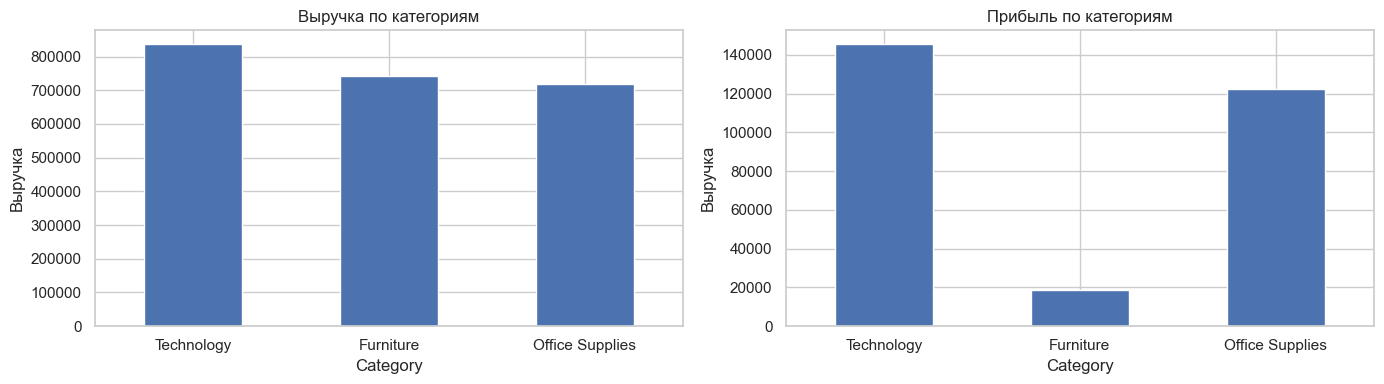

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

cat['Sales'].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Выручка по категориям')
axes[0].set_ylabel('Выручка')

cat['Profit'].plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Прибыль по категориям')
axes[1].set_ylabel('Выручка')

plt.tight_layout()
plt.show()

**Интерсайты:**
- **Technology** — лидер по прибыли (маржа ~14–15%), хотя по выручке может уступать Furniture.
- **Furniture** — большая выручка, но **самая низкая маржа**; в подкатегории Tables — убытки.
- **Office Supplies** — много заказов, стабильная маржа.

**Гипотеза для этапа 3:** проверить, что тянет Furniture вниз (Tables/Bookcases + скидки).

## 2.3. Продажи и прибыль по Sub-Category

Детализируем на 17 подкатегорий. Отмечаем отрицательную прибыль
(красным) — это кандидаты на пересмотр ценообразования.

In [63]:
sub = (df.groupby('Sub-Category', observed=True)
         .agg(
             Sales=('Sales','sum'),
             Profit=('Profit','sum'))
         .assign(Margin_pct=lambda x: x['Profit']/x['Sales']*100)
         .sort_values('Profit'))

sub.round(2)

,Sales,Profit,Margin_pct
Sub-Category,,,
Tables,206965.53,-17725.48,-8.56
Bookcases,114880.00,-3472.56,-3.02
Supplies,46673.54,-1189.10,-2.55
Fasteners,3024.28,949.52,31.40
Machines,189238.63,3384.76,1.79
Labels,12486.31,5546.25,44.42
Art,27118.79,6527.79,24.07
Envelopes,16476.40,6964.18,42.27
Furnishings,91705.16,13059.14,14.24


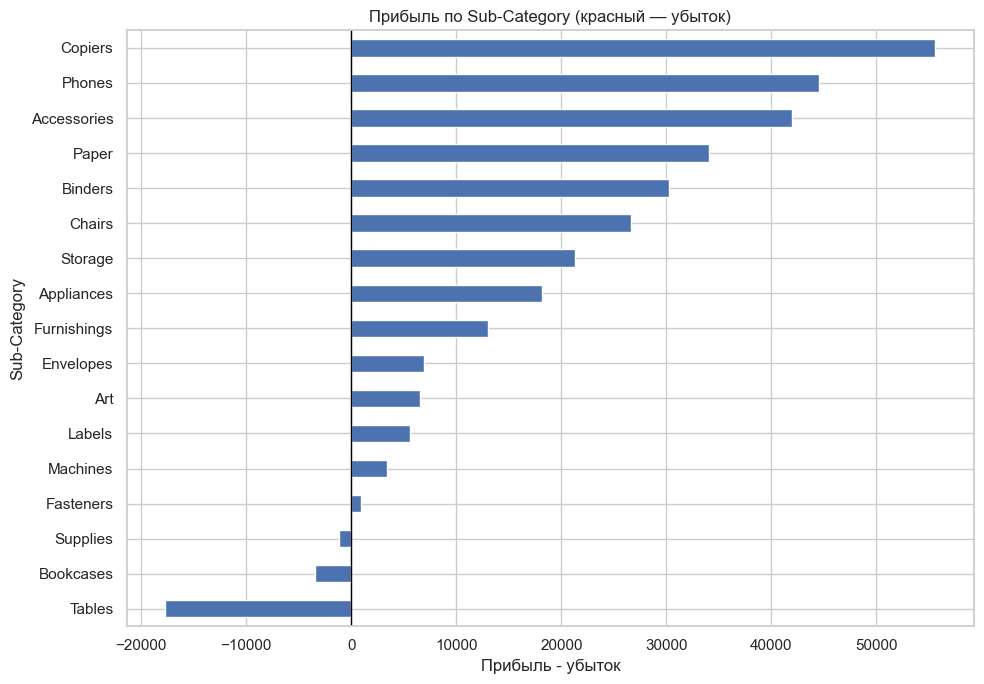

In [102]:
sub['Profit'].plot(kind='barh', figsize=(10, 7))

plt.axvline(0, color='black', linewidth=1)
plt.title('Прибыль по Sub-Category (красный — убыток)')
plt.xlabel('Прибыль - убыток')

plt.tight_layout()
plt.show()

**Интерсайты:**
- Отрицательная прибыль в **Tables**, **Bookcases** и части Supplies —
  чаще всего из-за скидок 30–50%.
- **Copiers**, **Phones**, **Accessories** — драйверы прибыли.
- Этап 3 докажет связь «убыток - высокая скидка» на количественном уровне.

## 2.4. Сегменты клиентов

Сравниваем Consumer / Corporate / Home Office по выручке, прибыли и марже.

In [79]:
seg = (df.groupby('Segment', observed=True)
         .agg(
             Sales=('Sales','sum'),
             Profit=('Profit','sum'),
             Customers=('Customer ID','nunique'),
             Orders=('Order ID','nunique')
         )
         .assign(Margin_pct=lambda x: x['Profit']/x['Sales']*100)
         .sort_values('Sales', ascending=False))
seg.round(2)

,Sales,Profit,Customers,Orders,Margin_pct
Segment,,,,,
Consumer,1161401.34,134119.21,409,2586,11.55
Corporate,706146.37,91979.13,236,1514,13.03
Home Office,429653.15,60298.68,148,909,14.03


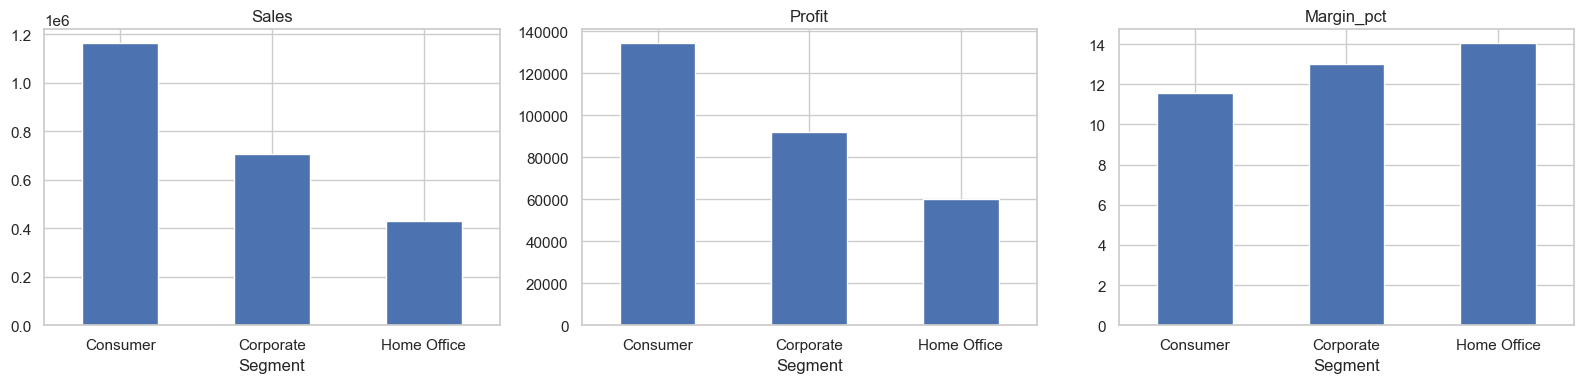

In [113]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ['Sales','Profit','Margin_pct']):
    seg[col].plot(kind='bar', ax=ax, rot=0)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Интерсайты:**
- **Consumer** - крупнейший по выручке (~50%), но может уступать по марже.
- **Corporate** - меньше заказов, но выше средний чек и стабильная маржа.
- **Home Office** - самый маленький сегмент, но часто с хорошей маржой.

**Рекомендация-гипотеза:** приоритет удержания - Corporate,
масштабирование - Consumer.

## 2.5. Регионы и штаты

Смотрим 4 региона и топ/антитоп штатов по прибыли.

In [114]:
region = (df.groupby('Region', observed=True)
            .agg(
                Sales=('Sales','sum'),
                Profit=('Profit','sum')
            )
            .assign(Margin_pct=lambda x: x['Profit']/x['Sales']*100)
            .sort_values('Profit', ascending=False))
region.round(2)

,Sales,Profit,Margin_pct
Region,,,
West,725457.82,108418.45,14.94
East,678781.24,91522.78,13.48
South,391721.90,46749.43,11.93
Central,501239.89,39706.36,7.92


In [125]:
state = (df.groupby('State', observed=True)
           .agg(
               Sales=('Sales','sum'),
               Profit=('Profit','sum')
           )
           .assign(Margin_pct=lambda x: x['Profit']/x['Sales']*100)
           .sort_values('Profit'))

print('--- АНТИ-ТОП-10 (убытки) ---')
state.head(10).round(2)

# print('--- ТОП-10 (прибыль) ---')
# state.tail(10).round(2)

--- АНТИ-ТОП-10 (убытки) ---


,Sales,Profit,Margin_pct
State,,,
Texas,170188.05,-25729.36,-15.12
Ohio,78258.14,-16971.38,-21.69
Pennsylvania,116511.91,-15559.96,-13.35
Illinois,80166.10,-12607.89,-15.73
North Carolina,55603.16,-7490.91,-13.47
Colorado,32108.12,-6527.86,-20.33
Tennessee,30661.87,-5341.69,-17.42
Arizona,35282.00,-3427.92,-9.72
Florida,89473.71,-3399.30,-3.80


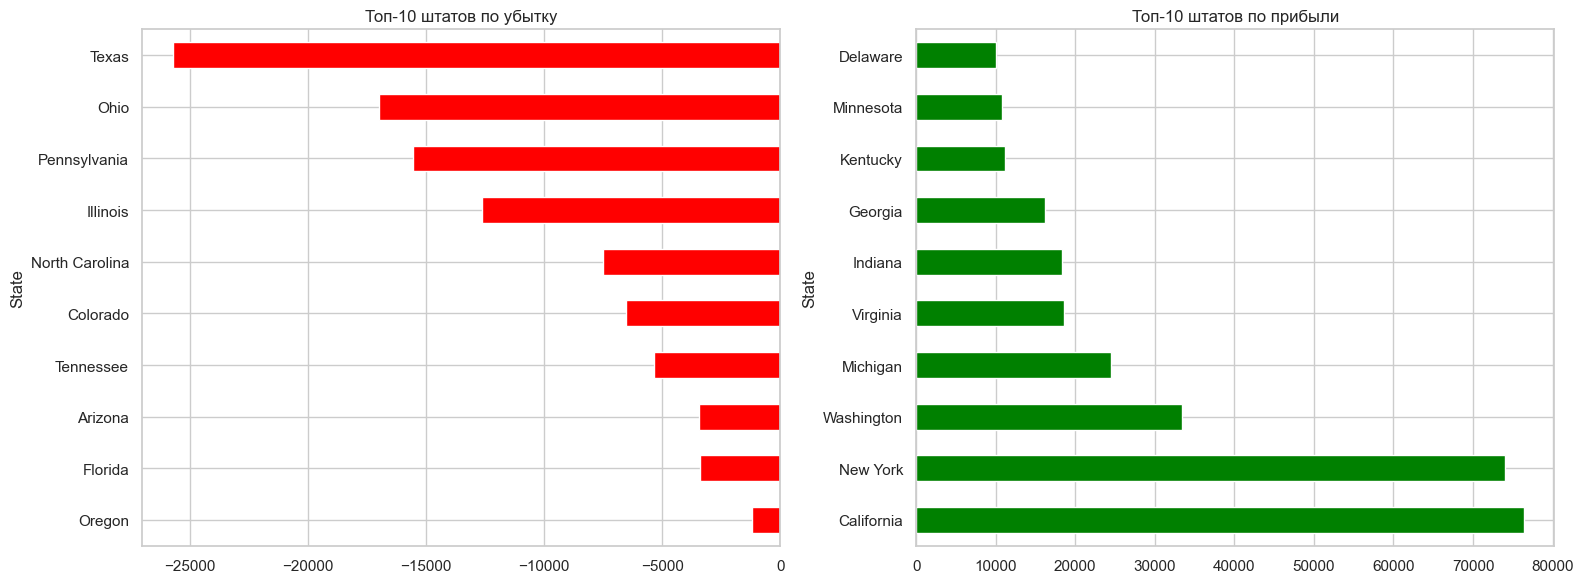

In [126]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

state.head(10)['Profit'].plot(kind='barh', ax=axes[0], color='red')
axes[0].set_title('Топ-10 штатов по убытку')
axes[0].invert_yaxis()

state.tail(10)['Profit'].plot(kind='barh', ax=axes[1], color='green')
axes[1].set_title('Топ-10 штатов по прибыли')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Интерсайты:**
- **West** и **East** — прибыльные регионы (California, New York — лидеры).
- **Central** и **South** — тянут вниз: Texas, Pennsylvania, Ohio, Illinois
  часто в красной зоне из-за агрессивных скидок?

**Гипотеза для этапа 3:** в убыточных штатах средняя скидка выше,
чем в прибыльных.

## 2.6. Динамика по годам

Выручка и прибыль по годам. Первое представление о тренде.

In [144]:
yearly = (df.assign(Year=df['Order Date'].dt.year)
            .groupby('Year')
            .agg(
                Sales=('Sales','sum'),
                Profit=('Profit','sum'))
            .assign(Margin_pct=lambda x: x['Profit']/x['Sales']*100))

yearly['Sales_YoY_%']  = yearly['Sales'].pct_change()  * 100
yearly['Profit_YoY_%'] = yearly['Profit'].pct_change() * 100

yearly.round(2)

,Sales,Profit,Margin_pct,Sales_YoY_%,Profit_YoY_%
Year,,,,,
2014,484247.50,49543.97,10.23,NaN,NaN
2015,470532.51,61618.60,13.10,-2.83,24.37
2016,609205.60,81795.17,13.43,29.47,32.74
2017,733215.26,93439.27,12.74,20.36,14.24


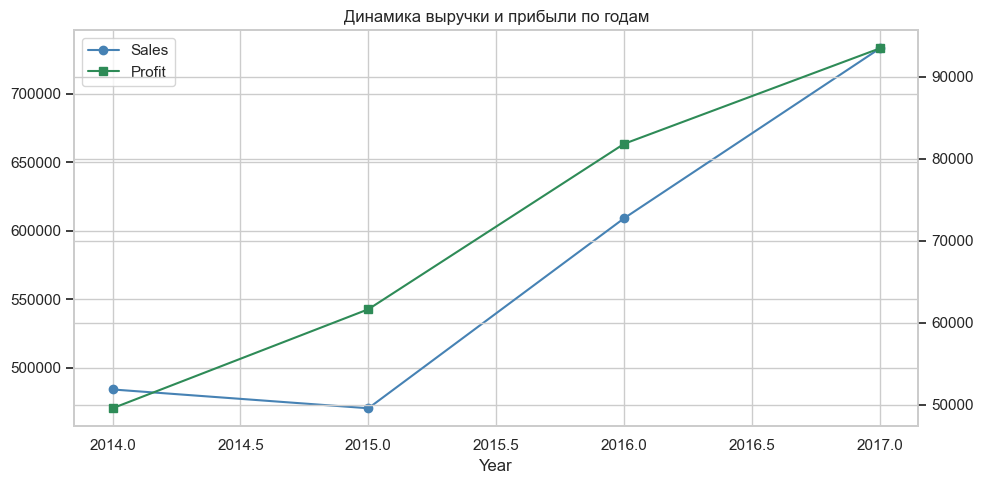

In [148]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

yearly['Sales'].plot(ax=ax1, marker='o', color='steelblue', label='Sales')
yearly['Profit'].plot(ax=ax2, marker='s', color='seagreen', label='Profit')


ax1.set_title('Динамика выручки и прибыли по годам')
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.tight_layout()
plt.show()

**Интерсайты:**
- Выручка растёт **каждый год** (2014 → 2017), примерно +20–30% YoY.
- Прибыль растёт, но **медленнее** выручки — маржа снижается →
  усиливается скидочная политика.
- Тренд «выручка растёт, маржа падает» — повод для этапа 3.

**Рекомендация-гипотеза:** пересмотреть рост скидок, иначе через 1–2 года
бизнес выйдет в ноль по прибыли.

## 2.7. Сезонность (по месяцам)

Усредняем по 4 годам, чтобы убрать годовой тренд и увидеть паттерн.

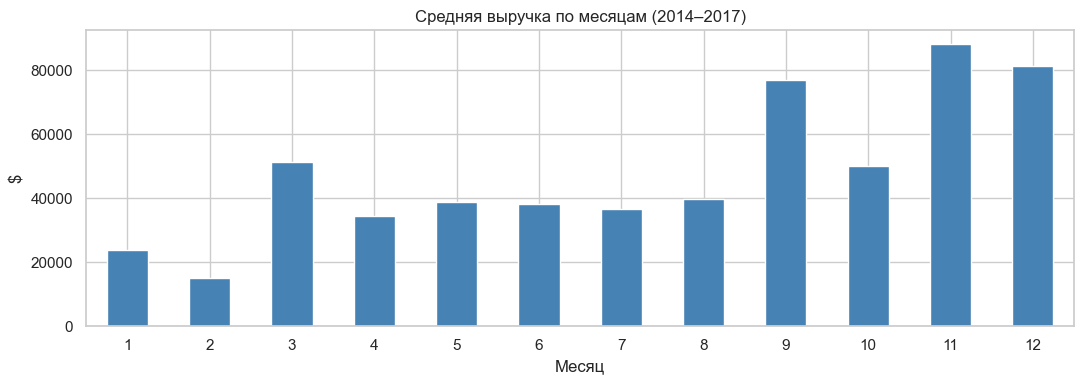

In [149]:
monthly = (df.assign(Month=df['Order Date'].dt.month,
                     Year=df['Order Date'].dt.year)
             .groupby(['Year','Month'])
             .agg(Sales=('Sales','sum'))
             .reset_index())

# средняя выручка по месяцу за 4 года
season = monthly.groupby('Month')['Sales'].mean().round(0)

season.plot(kind='bar', figsize=(11, 4), color='steelblue')
plt.title('Средняя выручка по месяцам (2014–2017)')
plt.xlabel('Месяц')
plt.ylabel('$')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Интерсайты:**
- Пик — **сентябрь, ноябрь, декабрь**.
- Провал — **январь–февраль**.
- Планирование запасов и промо — под пик.

**Рекомендация-гипотеза:** 

## 2.8. Итоговая сводка этапа 2

| Блок | Ключевой вывод |
|---|---|
| Общие KPI | Выручка $2.29M, прибыль $286K, маржа 12.5%, средняя скидка 15.6% |
| Category | Technology — драйвер маржи, Furniture — низкая маржа |
| Sub-Category | Tables, Bookcases — убыточные; Copiers, Phones — прибыльные |
| Segment | Consumer — объём, Corporate — стабильная маржа |
| Region/State | West/East прибыльные; Central/South тянут вниз (TX, PA, OH, FL) |
| Динамика | Выручка ↑, маржа ↓ — растущая скидочная нагрузка |
| Сезонность | Пик Q4 (сентябрь–декабрь), провал январь–февраль |

**Вопросы, уходящие в этап 3:**
1. При какой скидке прибыль уходит в минус?
2. Какие именно подкатегории и штаты страдают от скидок?
3. Как перераспределить скидочную политику, чтобы вернуть прибыль?

**Чек-лист этапа 2**

- [x] Посчитаны общие KPI (выручка, прибыль, маржа, средний чек, средняя скидка)
- [x] Разбивка по Category (Sales, Profit, Margin, Share)
- [x] Разбивка по Sub-Category (выделены убыточные)
- [x] Разбивка по Segment
- [x] Разбивка по Region и State (топ-10 / анти-топ-10)
- [x] Динамика по годам + YoY
- [x] Сезонность по месяцам
- [x] Сводка + вопросы к этапу 3
- [x] Блок в README